In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(
    "rows.csv",
    usecols=[
        "Complaint ID",
        "Product",
        "Consumer complaint narrative"
    ],
    low_memory=False
)
df.head()

,Product,Consumer complaint narrative,Complaint ID
0,Checking or savings account,NaN,3238275
1,Checking or savings account,NaN,3238228
2,Debt collection,NaN,3237964
3,"Credit reporting, credit repair services, or o...",NaN,3238479
4,Checking or savings account,NaN,3238460


In [3]:
print("Shape : " , df.shape)
print("Columns : " , df.columns)

Shape :  (1282355, 3)
Columns :  Index(['Product', 'Consumer complaint narrative', 'Complaint ID'], dtype='str')


In [4]:
display(df.isnull().sum().sort_values(ascending=False))

Consumer complaint narrative    898791
Product                              0
Complaint ID                         0
dtype: int64

1- Hangi sütun müşteri şikâyetinin yazılı metnini tutuyor?
2- Hangi sütun şikâyetin ait olduğu ürün/hizmet kategorisini gösteriyor?

In [5]:
#Consumer complaint narrative sütünü müşteri şikayatlerini gösteriyor.

In [6]:
complaints  = df.copy()
complaints.head(5)

,Product,Consumer complaint narrative,Complaint ID
0,Checking or savings account,NaN,3238275
1,Checking or savings account,NaN,3238228
2,Debt collection,NaN,3237964
3,"Credit reporting, credit repair services, or o...",NaN,3238479
4,Checking or savings account,NaN,3238460


1-Product sütununda eksik kayıt olup olmadığını kontrol et.

In [7]:
complaints["Product"].isnull().sum()

np.int64(0)

2- complaint narrative sütunundaki NaN değerleri kaldır.

In [8]:
complaints = complaints.dropna(subset=["Consumer complaint narrative"])

In [9]:
complaints.isnull().sum()

Product                         0
Consumer complaint narrative    0
Complaint ID                    0
dtype: int64

3 - Yalnızca boşluk içeren metinleri tespit et.

In [10]:
complaints[complaints["Consumer complaint narrative"].str.strip() == " "]

,Product,Consumer complaint narrative,Complaint ID


4- Metinlerin başındaki ve sonundaki gereksiz boşlukları kaldır. Temizlikten önceki ve sonraki satır sayılarını karşılaştır.

In [11]:
complaints["Consumer complaint narrative"].str.len().sum()

np.int64(415020574)

In [12]:
complaints["Consumer complaint narrative"] = complaints["Consumer complaint narrative"].str.strip()

In [13]:
complaints["Consumer complaint narrative"].str.len().sum()

np.int64(415020574)

Soru  - Bir şikâyet metni eksikse neden bu alanı ortalama, mod veya başka bir şikâyet metniyle doldurmamalıyız?

In [14]:
#Metinler sayısal verilerden farklıdır. Aynı zamanda cümlenin doğallığı ve anlamı bozulur.

Gerçek dünyada aynı müşteri şikâyeti birden fazla kez kaydedilmiş olabilir.
1-Tamamen aynı satırları bul.

In [15]:
duplicates = complaints[
    complaints["Consumer complaint narrative"].duplicated(keep=False)
]
duplicates

,Product,Consumer complaint narrative,Complaint ID
30629,"Credit reporting, credit repair services, or o...",There are many mistakes appear in my report wi...,3187982
30735,"Credit reporting, credit repair services, or o...",There are many mistakes appear in my report wi...,3187954
30795,"Credit reporting, credit repair services, or o...",There are many mistakes appear in my report wi...,3188091
30807,"Credit reporting, credit repair services, or o...",There are many mistakes appear in my report wi...,3188119
30857,"Credit reporting, credit repair services, or o...",There are many mistakes appear in my report wi...,3187953
...,...,...,...
912254,Debt collection,This company continues to report on my credit ...,1291611
912301,Credit reporting,This item is past the Fair Credit Reporting Ac...,1291682
912350,Debt collection,"I received a letter XXXX XXXX, 2014 from a col...",1290800
912429,Debt collection,"I have reached out to the company. However, th...",1292216


In [16]:
duplicates.shape[0]

26404

In [17]:
complaints.duplicated().sum()

np.int64(0)

3-Bu iki sonucun neden farklı olabileceğini araştır.

In [18]:
#Çünkü birinde tüm data genelinde aynı olan kayıtlara bakıyoruz. Bu da 0 olarak geliyor. Ama aynı metne sahip olanları yani daha spesifik bir durumda ise tekrar eden 26404 tane veri geldiğini görüyoruz.

4- Aynı metnin farklı Product etiketlerine sahip olup olmadığını kontrol et.

In [19]:
product_counts = complaints.groupby(
    "Consumer complaint narrative"
)["Product"].nunique()

product_counts[product_counts > 1]

Consumer complaint narrative
A full payment was made but I only wanted the regular monthly payment! I called and said I could not afford that! They refused to reverse the debit payment! So I called my bank and opened a dispute then they credited the money and only took the monthly payment out to them! Then I just received a letter I lost the dispute and it will be pulled back out on XX/XX/XXXX!                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                           

4- Tekrarlanan kayıtlar için bir temizleme kararı ver ve nedenini yaz.

In [20]:
complaints = complaints.drop_duplicates(
    subset=["Consumer complaint narrative", "Product"],
    keep="first"
).copy()


#cunku ayni metinlerin ve urunlerin test ve trainde birlikte olmasi modelde overfitting e sebebiyet verir. Data Lake olusabilir.

Soru - Aynı şikâyet metni iki farklı ürün kategorisinde bulunuyorsa hangisini doğru kabul etmeliyiz?

In [21]:
#Eğer aynı metin iki farklı ürün kategorisi içinde kullanıldıysa ikisinide kabul edebiliriz. Çünkü bir yorum iki ayrı kategori içinde uygun olabilir.

Ürün kategorilerini analiz et

1- Kaç farklı ürün kategorisi olduğunu bul.

In [22]:
complaints["Product"].nunique()

18

2- Bütün kategorilerin kayıt sayılarını hesapla.

In [23]:
complaints["Product"].value_counts()

Product
Debt collection                                                                 84317
Credit reporting, credit repair services, or other personal consumer reports    80466
Mortgage                                                                        52945
Credit reporting                                                                29827
Student loan                                                                    21781
Credit card or prepaid card                                                     21292
Credit card                                                                     18757
Bank account or service                                                         14856
Checking or savings account                                                     12858
Consumer Loan                                                                    9443
Vehicle loan or lease                                                            5720
Money transfer, virtual currency, or money ser

3-En fazla şikâyet içeren 10 kategoriyi görüntüle.

In [24]:
complaints["Product"].value_counts().sort_values(ascending=False).head(10)

Product
Debt collection                                                                 84317
Credit reporting, credit repair services, or other personal consumer reports    80466
Mortgage                                                                        52945
Credit reporting                                                                29827
Student loan                                                                    21781
Credit card or prepaid card                                                     21292
Credit card                                                                     18757
Bank account or service                                                         14856
Checking or savings account                                                     12858
Consumer Loan                                                                    9443
Name: count, dtype: int64

4- İlk dört kategoriyi belirle.
5- Bu dört kategorinin yüzdelik dağılımını hesapla.
6- Sonuçları bir çubuk grafikle göster.


In [25]:
top_4 = complaints["Product"].value_counts(normalize=True).head(4)

print(top_4)

Product
Debt collection                                                                 0.229670
Credit reporting, credit repair services, or other personal consumer reports    0.219180
Mortgage                                                                        0.144216
Credit reporting                                                                0.081245
Name: proportion, dtype: float64


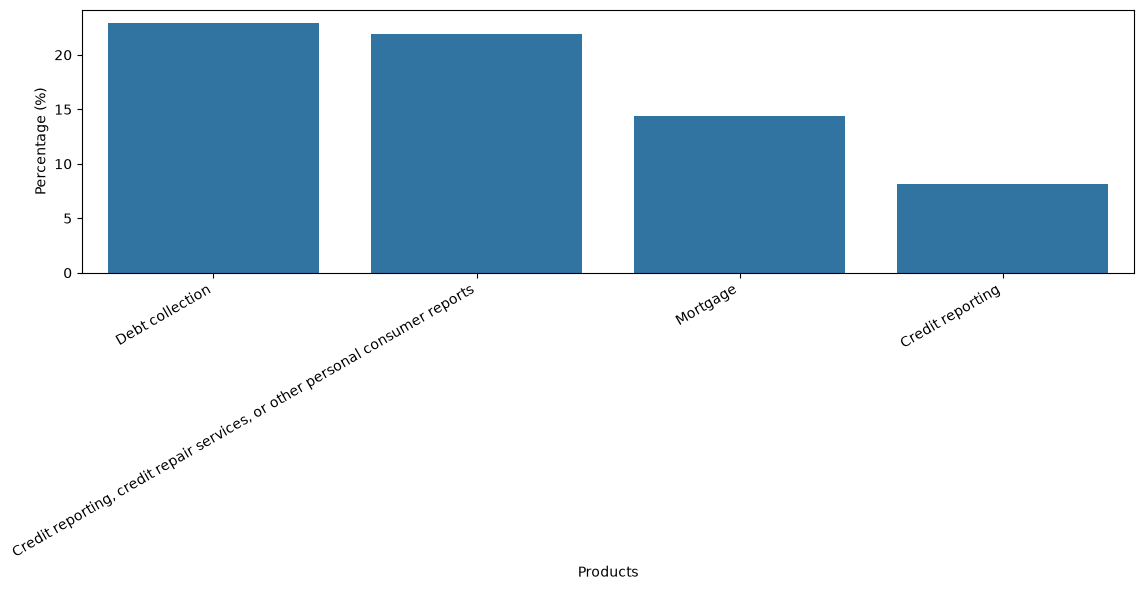

In [26]:
plt.figure(figsize=(12, 6))

sns.barplot(x=top_4.index, y=top_4.values * 100)

plt.xlabel("Products")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Metin uzunluklarını analiz et
1- Her şikâyetin kaç karakter olduğunu hesapla.

In [27]:
complaints["Consumer complaint narrative"].str.len()

29904      695
30629       69
31078      668
31458     1608
33083      419
          ... 
912543    2267
912546     561
912550     359
912552     126
912553     588
Name: Consumer complaint narrative, Length: 367123, dtype: int64

2- Her şikâyetin yaklaşık kaç kelime içerdiğini hesapla.
3- Ortalama metin uzunluğunu bul.

In [28]:
complaints["Consumer complaint narrative"].str.split().str.len()

29904     127
30629      11
31078     122
31458     277
33083      73
         ... 
912543    415
912546    101
912550     67
912552     17
912553    109
Name: Consumer complaint narrative, Length: 367123, dtype: int64

In [29]:
complaints["Consumer complaint narrative"].str.split().str.len().mean()

np.float64(201.8209646358305)

4- En uzun ve en kısa şikâyeti tespit et.

In [30]:
complaints["Consumer complaint narrative"].str.len().max()

np.int64(31735)

In [31]:
complaints["Consumer complaint narrative"].str.len().min()

np.int64(5)

5- Metin uzunluklarının dağılımını histogramla göster.

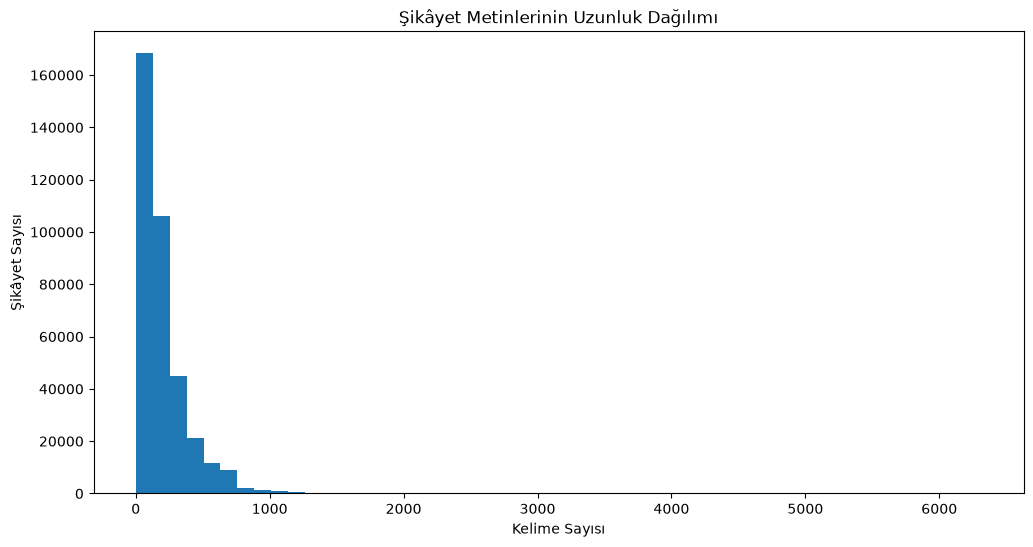

In [32]:
complaints["word_count"] = (
    complaints["Consumer complaint narrative"]
    .str.split()
    .str.len()
)



plt.figure(figsize=(12, 6))

plt.hist(complaints["word_count"], bins=50)

plt.xlabel("Kelime Sayısı")
plt.ylabel("Şikâyet Sayısı")
plt.title("Şikâyet Metinlerinin Uzunluk Dağılımı")

plt.show()

6- Çok kısa ve çok uzun metinleri incele.

In [33]:
complaints.nsmallest(
    10, "word_count"
)[["Product", "Consumer complaint narrative", "word_count"]]

,Product,Consumer complaint narrative,word_count
104708,"Money transfer, virtual currency, or money ser...",Throughoutthelastfewmonthswehavehadawebsite(XX...,1
484346,Debt collection,Fraud,1
812963,Mortgage,OcwenLetterXXXX.pdf,1
849421,Bank account or service,fradulent,1
39049,"Credit reporting, credit repair services, or o...",Unauthorized Inquiries.,2
45615,"Credit reporting, credit repair services, or o...",inaccurate information,2
67869,"Credit reporting, credit repair services, or o...",INACCURATE INFORMATION,2
105162,"Credit reporting, credit repair services, or o...",Account fraud,2
142680,"Credit reporting, credit repair services, or o...",Fraudulent Inquiries.,2
145608,"Credit reporting, credit repair services, or o...",Identity theft.,2


In [34]:
complaints.nlargest(
    10, "word_count"
)[["Product", "Consumer complaint narrative", "word_count"]]

,Product,Consumer complaint narrative,word_count
483464,Vehicle loan or lease,XX/XX/XXXX SECTION 4- COMPLAINT Carhop Additio...,6314
241123,"Money transfer, virtual currency, or money ser...",Paypal Has Unfairly & Unjustly Limited My Acco...,5988
329547,Credit card or prepaid card,I am due a referral bonus on the XXXX XXXX car...,5735
256769,Mortgage,TO THE CONSUMER PROTECTION AGENCY cfbp* FROM :...,5729
440374,Debt collection,Alleged Account # XXXX FINAL RESPONSE TO JPMOR...,5573
386174,Mortgage,From : XXXX XXXX XXXX XXXX : XXXXXXXXXXXX XXXX...,5542
109416,Checking or savings account,"Dear XXXX, COMPLAINT ISSUE I am a retired XXXX...",5541
118981,Student loan,This is my second time filing a complaint on t...,5421
293754,Debt collection,"BROCK & SCOTT PLLC VIOLATED A COURT ORDER, TRE...",5343
293561,Debt collection,"XXXX XXXX XXXX XXXX VIOLATED A COURT ORDER, TR...",5341


Soru : Çok uzun şikâyet metinleri ileride BERT gibi Transformer modellerini kullanırken ne tür problemler oluşturabilir?

In [ ]:
#Daha uzun metinler  bellek kullanımını arttırır. Aynı zamanda kullancağımız modellerde belirteceğimiz token sayılarına göre kırpma uygulamak gerekebilir ve böylece anlamsal butunlugu kaybetmiş oluruz. Bunların önüne geçmek için metinleri kısaltabilir veya truncation , chunking gibi yöntemler kullanabiliriz.


En büyük dört kategoriyi seç
1-En fazla kayıt içeren dört kategoriyi seç.
2- Yalnızca bu kategorilere ait şikâyetleri içeren yeni bir DataFrame oluştur.


In [36]:
top_4.index

Index(['Debt collection',
       'Credit reporting, credit repair services, or other personal consumer reports',
       'Mortgage', 'Credit reporting'],
      dtype='str', name='Product')

In [41]:
new_df = complaints[complaints["Product"].isin(top_4.index)].drop(columns=["word_count"]).copy()

In [42]:
new_df.shape

(247555, 3)

In [43]:
new_df["Product"].value_counts(normalize=True)

Product
Debt collection                                                                 0.340599
Credit reporting, credit repair services, or other personal consumer reports    0.325043
Mortgage                                                                        0.213872
Credit reporting                                                                0.120486
Name: proportion, dtype: float64

In [57]:
new_df = new_df.drop_duplicates(
    subset=["Consumer complaint narrative"],
    keep="first"
).copy()

new_df.reset_index(drop=True, inplace=True)

Eğitim ve test verilerini ayır
1- Temizlenmiş dört kategorili veri setini kullan.
2- Verinin %80'ini eğitim, %20'sini test olarak ayır.
3- random_state=42 kullan.

In [58]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    new_df,
    test_size=0.20,
    stratify=new_df["Product"],
    random_state=42
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

4- Eğitim ve test verilerinin kategori dağılımlarını karşılaştır.

In [59]:
print("Train dağılımı:")
print(train_df["Product"].value_counts(normalize=True) * 100)

print("\nTest dağılımı:")
print(test_df["Product"].value_counts(normalize=True) * 100)

Train dağılımı:
Product
Debt collection                                                                 34.056836
Credit reporting, credit repair services, or other personal consumer reports    32.507122
Mortgage                                                                        21.394945
Credit reporting                                                                12.041097
Name: proportion, dtype: float64

Test dağılımı:
Product
Debt collection                                                                 34.057341
Credit reporting, credit repair services, or other personal consumer reports    32.505607
Mortgage                                                                        21.394945
Credit reporting                                                                12.042107
Name: proportion, dtype: float64


5- Aynı şikâyet metninin her iki kümede bulunmadığını kontrol et.

In [61]:
common_texts = set(train_df["Consumer complaint narrative"]).intersection(set(test_df["Consumer complaint narrative"]))

print("Ortak şikâyet metni sayısı:", len(common_texts))

Ortak şikâyet metni sayısı: 0


Soru : stratify kullanmazsak küçük bir veri setinde ne tür problemler yaşayabiliriz?    

In [ ]:
#Bazi kategoriler az dagilabilir bu da egitim ve test kumesinin dengesiz olmasina yol acabilir. Bu durum modelin yeterinde ogrenememesine , performans sonuclarinin guvenilir olmamasina yol acabilir.

Dengeli 5.000 kayıtlık eğitim verisi oluştur
1- Yalnızca train_df içinden kayıt seç.
2- Dört kategorinin her birinden rastgele 1.250 kayıt al.
3- random_state=42 kullan.
4- Seçilen kayıtları tek bir DataFrame'de birleştir.

In [62]:
balanced_train_df = (
    train_df.groupby("Product", group_keys=False)
    .sample(n=1250, random_state=42)
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

In [64]:
print("Train:", train_df.shape)
print("Balanced Train:", balanced_train_df.shape)
print("Test:", test_df.shape)

print(balanced_train_df["Product"].value_counts())

Train: (197972, 3)
Balanced Train: (5000, 3)
Test: (49493, 3)
Product
Credit reporting, credit repair services, or other personal consumer reports    1250
Debt collection                                                                 1250
Credit reporting                                                                1250
Mortgage                                                                        1250
Name: count, dtype: int64


Veri setini kaydet
1- Dengeli eğitim verisini complaints_train_5000.csv olarak kaydet.
2- Test verisini complaints_test.csv olarak kaydet.
3- Eğitim veri setinde eksik metin kalmadığını kontrol et.
4- Her eğitim kategorisinin 1.250 kayıt içerdiğini doğrula.
5- Eğitim ve test kümelerinde ortak şikâyet metni olmadığını kontrol et.
6- Verileri UTF-8 formatında kaydet.

In [65]:
print("NaN sayısı:", balanced_train_df["Consumer complaint narrative"].isna().sum())

print(
    "Boş metin sayısı:",
    balanced_train_df["Consumer complaint narrative"].str.strip().eq("").sum()
)

NaN sayısı: 0
Boş metin sayısı: 0


In [69]:
print(balanced_train_df["Product"].value_counts())


Product
Credit reporting, credit repair services, or other personal consumer reports    1250
Debt collection                                                                 1250
Credit reporting                                                                1250
Mortgage                                                                        1250
Name: count, dtype: int64


In [70]:
common_texts = train_texts.intersection(test_texts)

print("Ortak metin sayısı:", len(common_texts))

Ortak metin sayısı: 0


In [68]:
balanced_train_df.to_csv(
    "complaints_train_5000.csv",
    index=False,
    encoding="utf-8"
)

test_df.to_csv(
    "complaints_test.csv",
    index=False,
    encoding="utf-8"
)

print("Veri setleri başarıyla kaydedildi!")

Veri setleri başarıyla kaydedildi!
